In [17]:
import sys
sys.path.append("../src")

import numpy as np
import matplotlib.pyplot as plt
from bayes import update_gaussian

## Simulation of belief updating with a pessimistic prior and noisy feedback values after 50 trials

In [18]:

#simulating an agent with a pessimistic prior and
#50 noisy feedback values around its true competence

rng = np.random.default_rng(0)   # random number generator

theta = 0.8      # true competence
m = 0.2          # inicial pessimist belief
s2 = 0.1         # inicial uncertainty 
sigma2 = 0.05    # feedback noise 

ms = []         
Ks = []         
s2s = []         

#after each feedback track the belief m, uncertainty s2 and Kalman gain

for t in range(50):
    y = rng.normal(theta, np.sqrt(sigma2)) 
    K= s2/(s2+sigma2) 
    Ks.append(K) 
    m, s2 = update_gaussian(m, s2, y, sigma2)  
    ms.append(m)  
    s2s.append(s2)  

   
   

In [19]:
#checking to see if the values were added

print(ms)
print(s2s)
print(K)

[0.6187427547460604, 0.6794298346685296, 0.7547935556410001, 0.7700519608941532, 0.7537190019706173, 0.7732784035613742, 0.8157190530008414, 0.8387843104566596, 0.818137542772524, 0.7894618869899336, 0.7782592527571293, 0.7807377741290165, 0.7436540363278195, 0.7441659439364977, 0.7297943245085365, 0.7241255800969836, 0.7215069750455341, 0.7219267674704498, 0.7306506966306691, 0.7454049590463739, 0.746607462142785, 0.7625604869760807, 0.7578242087720481, 0.7627538345834083, 0.7721369028029512, 0.7739816154840258, 0.7688822299654242, 0.7627423601494431, 0.760535818919803, 0.7634440585106061, 0.7574376601778489, 0.7573080989273128, 0.757519684195492, 0.7622564107193562, 0.7646717016565987, 0.7678166893776823, 0.7647762304174947, 0.7649383415865265, 0.7702640100115499, 0.7792436975678795, 0.7729598587881432, 0.7815613596944684, 0.788903555878098, 0.7930789038438975, 0.7945306658834796, 0.793138710159122, 0.8001468075473286, 0.8091814524412835, 0.8171345100478326, 0.8226183047308694]
[0.03

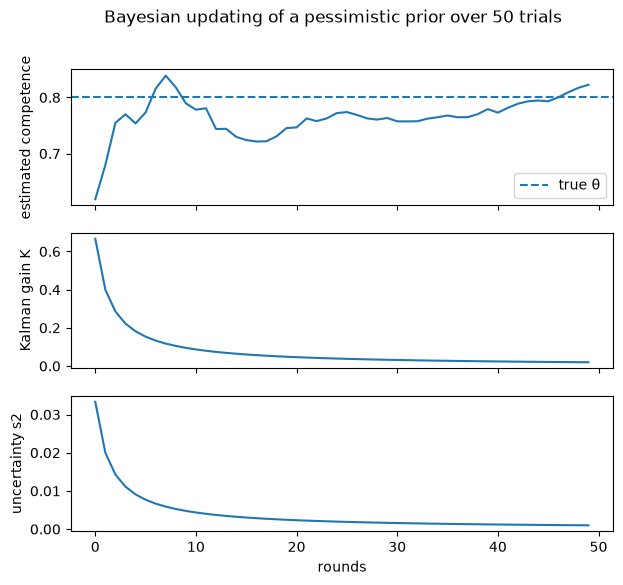

In [20]:
#plotting

fig, axes = plt.subplots(3, 1, figsize=(7, 6), sharex=True)
fig.suptitle("Bayesian updating of a pessimistic prior over 50 trials")

axes[0].plot(ms)
axes[0].axhline(theta, linestyle="--", label="true θ")  
axes[0].set_ylabel("estimated competence")
axes[0].legend()

axes[1].plot(Ks)
axes[1].set_ylabel("Kalman gain K")    

axes[2].plot(s2s)
axes[2].set_ylabel("uncertainty s2")
axes[2].set_xlabel("rounds")

plt.show()

## Volatility – adding uncertainty before each feedback

In [21]:
# simulating belief updating with an agent with a pessimistic
# prior, but this time it assumes its competence can change
# between trials, so before each noisy feedback q is added
# to its uncertainty s2

def run_simulation(q, n_trials=50):
    rng = np.random.default_rng(0)
    theta = 0.8
    m = 0.2
    s2 = 0.1
    sigma2 = 0.05
    Ks = []

    for t in range(n_trials):
        s2= s2 + q # adding q to uncertainty
        y= rng.normal(theta, np.sqrt(sigma2))
        K= s2/(s2+sigma2)
        Ks.append(K)
        m,s2= update_gaussian(m,s2,y,sigma2)

    return Ks

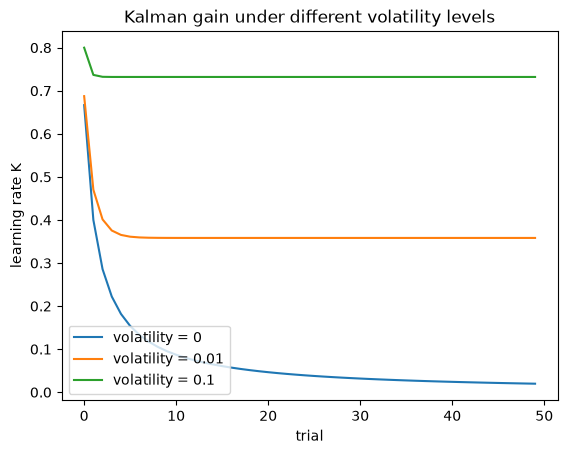

In [22]:
#plotting for different volaitly levels

for q in [0, 0.01, 0.1]:
    Ks = run_simulation(q)
    plt.plot(Ks, label=f"volatility = {q}")
    plt.xlabel("trial")
plt.ylabel("learning rate K")
plt.title("Kalman gain under different volatility levels")
plt.legend()
plt.show()